# Breast Cancer Classification

**Dataset:** Wisconsin Diagnostic Breast Cancer (WDBC)  
**Task:** Binary classification of breast tumors as benign or malignant.

This notebook builds and evaluates two classification pipelines: polynomial Logistic Regression and Random Forest. The main focus is on comparing their performance and selecting a probability threshold using cross-validation rather than tuning the threshold on the held-out test set.

## Project Roadmap

1. Load the dataset and prepare the target.
2. Split the data using stratified sampling.
3. Train baseline Logistic Regression and Random Forest models.
4. Select classification thresholds using cross-validation.
5. Evaluate the final models on the held-out test set.
6. Inspect model features and summarize the findings.

## Evaluation

The positive class is **Malignant** (`1`). Precision, recall, and F1-score are therefore reported for malignant cases. In a medical screening context, false negatives are especially important because they represent malignant cases classified as benign.

## 1. Data Loading and Preparation

The input file `wdbc.data` is expected at `data/wdbc.data` relative to the repository root. It contains an ID, a diagnosis label, and 30 numeric measurements computed from digitized images of breast mass samples.

The diagnosis is encoded as `B = 0` (Benign) and `M = 1` (Malignant). The ID column is removed because it is an identifier rather than a predictive measurement.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42

In [1]:
columns = [
    "ID", "diagnosis",
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst"
]

data_path = Path("data/wdbc.data")
if not data_path.exists():
    data_path = Path("../data/wdbc.data")

df = pd.read_csv(data_path, header=None, names=columns)

df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})
X = df.drop(columns=["ID", "diagnosis"])
y = df["diagnosis"]

print(f"Dataset shape: {df.shape}")
print(f"Benign samples: {(y == 0).sum()}")
print(f"Malignant samples: {(y == 1).sum()}")

Dataset shape: (569, 32)\nBenign samples: 357\nMalignant samples: 212\n

## 2. Train-Test Split

A stratified 80/20 split preserves the original class proportions in both subsets. The test set is held out for the final evaluation.

In [1]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")

Training samples: 455\nTest samples: 114\n

## 3. Baseline Models

### 3.1 Polynomial Logistic Regression

Polynomial features of degree 2 allow Logistic Regression to model nonlinear relationships and interactions between the original measurements. Standardization is applied after polynomial expansion and before fitting the classifier.

In [ ]:
logreg_model = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000))
])

logreg_model.fit(X_train, y_train)

In [1]:
y_pred_logreg_default = logreg_model.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_logreg_default))
print(f"Accuracy:  {accuracy_score(y_test, y_pred_logreg_default):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_logreg_default):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_logreg_default):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_logreg_default):.4f}")

Confusion matrix:\n[[72  0]\n [ 3 39]]\nAccuracy:  0.9737\nPrecision: 1.0000\nRecall:    0.9286\nF1-score:  0.9630\n

### 3.2 Random Forest

Random Forest is used as a tree-based model for comparison. Class weighting is set to `balanced` to account for the unequal class frequencies in the training data.

In [ ]:
rf_model = Pipeline([
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

In [1]:
y_pred_rf_default = rf_model.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_rf_default))
print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf_default):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf_default):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf_default):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_rf_default):.4f}")

Confusion matrix:\n[[72  0]\n [ 4 38]]\nAccuracy:  0.9649\nPrecision: 1.0000\nRecall:    0.9048\nF1-score:  0.9500\n

## 4. Probability Threshold Selection

Both classifiers produce probabilities for the malignant class. The default decision threshold is 0.50, but a lower threshold can increase recall at the cost of precision.

To avoid choosing the threshold from test-set outcomes, out-of-fold probabilities are generated on the training data using five-fold cross-validation. The threshold that maximizes the pooled out-of-fold F1-score is selected for each model.

In [1]:
thresholds = np.arange(0.01, 0.95, 0.01)

logreg_oof_probs = cross_val_predict(
    logreg_model,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

rf_oof_probs = cross_val_predict(
    rf_model,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)[:, 1]

logreg_cv_f1 = [
    f1_score(y_train, (logreg_oof_probs >= threshold).astype(int))
    for threshold in thresholds
]
rf_cv_f1 = [
    f1_score(y_train, (rf_oof_probs >= threshold).astype(int))
    for threshold in thresholds
]

logreg_threshold = thresholds[np.argmax(logreg_cv_f1)]
rf_threshold = thresholds[np.argmax(rf_cv_f1)]

print(f"Logistic Regression threshold: {logreg_threshold:.2f}")
print(f"Logistic Regression CV F1:      {max(logreg_cv_f1):.4f}")
print(f"Random Forest threshold:       {rf_threshold:.2f}")
print(f"Random Forest CV F1:           {max(rf_cv_f1):.4f}")

Logistic Regression threshold: 0.40\nLogistic Regression CV F1:      0.9733\nRandom Forest threshold:       0.36\nRandom Forest CV F1:           0.9595\n

## 5. Final Test-Set Evaluation

The thresholds selected using training-set cross-validation are applied once to the held-out test set. The confusion matrix uses the order `[[TN, FP], [FN, TP]]`.

In [1]:
logreg_test_probs = logreg_model.predict_proba(X_test)[:, 1]
rf_test_probs = rf_model.predict_proba(X_test)[:, 1]

y_pred_logreg = (logreg_test_probs >= logreg_threshold).astype(int)
y_pred_rf = (rf_test_probs >= rf_threshold).astype(int)

for name, predictions in [
    ("Polynomial Logistic Regression", y_pred_logreg),
    ("Random Forest", y_pred_rf)
]:
    print(f"--- {name} ---")
    print(confusion_matrix(y_test, predictions))
    print(classification_report(
        y_test,
        predictions,
        target_names=["Benign", "Malignant"],
        digits=4
    ))

--- Polynomial Logistic Regression ---
[[71  1]
 [ 2 40]]
              precision    recall  f1-score   support

      Benign     0.9726    0.9861    0.9793        72
   Malignant     0.9756    0.9524    0.9639        42

    accuracy                         0.9737       114
   macro avg     0.9741    0.9692    0.9716       114
weighted avg     0.9737    0.9737    0.9736       114

--- Random Forest ---
[[71  1]
 [ 3 39]]
              precision    recall  f1-score   support

      Benign     0.9595    0.9861    0.9726        72
   Malignant     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114


### 5.1 Model Comparison

| Model | Threshold | Accuracy | Precision (Malignant) | Recall (Malignant) | F1 (Malignant) |
|:---|---:|---:|---:|---:|---:|
| Polynomial Logistic Regression | 0.40 | 0.9737 | 0.9756 | 0.9524 | **0.9639** |
| Random Forest | 0.36 | 0.9649 | 0.9750 | 0.9286 | 0.9512 |

Polynomial Logistic Regression performs better on this split, with higher recall and F1-score for the malignant class. It identifies 40 of the 42 malignant test samples, while Random Forest identifies 39.

These results are based on one stratified hold-out split. They should not be interpreted as clinical performance or as evidence of generalization to other populations.

## 6. Model Interpretation

### 6.1 Polynomial Logistic Regression Coefficients

The chart below shows the largest absolute coefficients in the polynomial feature space. Since the inputs are standardized after polynomial expansion, coefficient magnitudes describe the fitted transformed model and should not be interpreted as direct effects in the original measurement units.

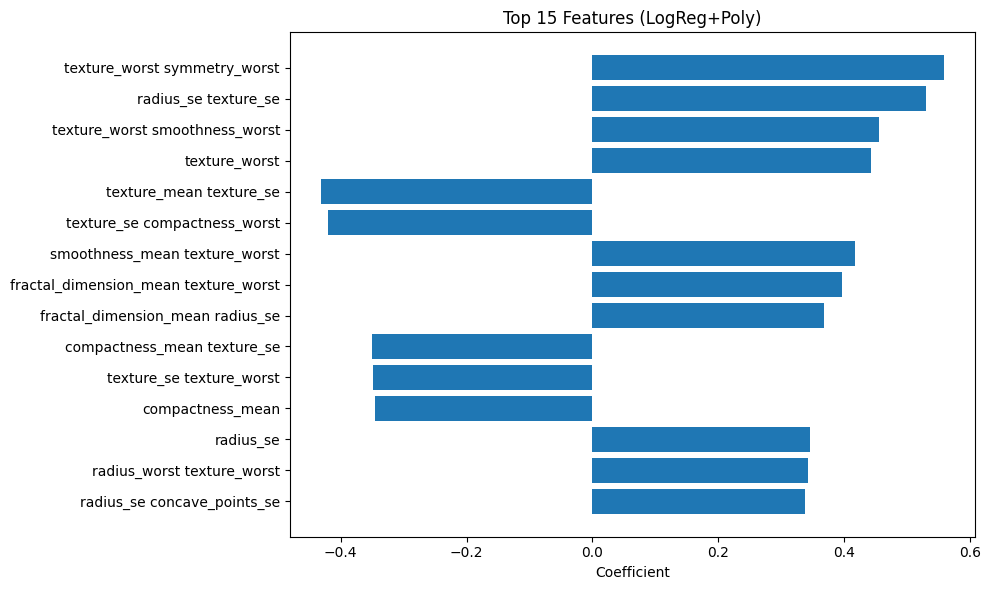

In [1]:
poly = logreg_model.named_steps["poly"]
classifier = logreg_model.named_steps["classifier"]
feature_names = poly.get_feature_names_out(X_train.columns)
coefficients = classifier.coef_[0]

coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})
top_coefficients = coefficient_table.loc[
    coefficient_table["coefficient"].abs().nlargest(15).index
].sort_values("coefficient")

plt.figure(figsize=(10, 6))
plt.barh(top_coefficients["feature"], top_coefficients["coefficient"])
plt.xlabel("Coefficient")
plt.title("Top 15 Polynomial Logistic Regression Coefficients")
plt.tight_layout()
plt.show()

### 6.2 Permutation Importance

Permutation importance measures how much the model's F1-score decreases when one feature is randomly shuffled. The following analysis is retained as an exploratory view of feature relevance on the held-out test set; it is not used to select the model or tune its threshold.

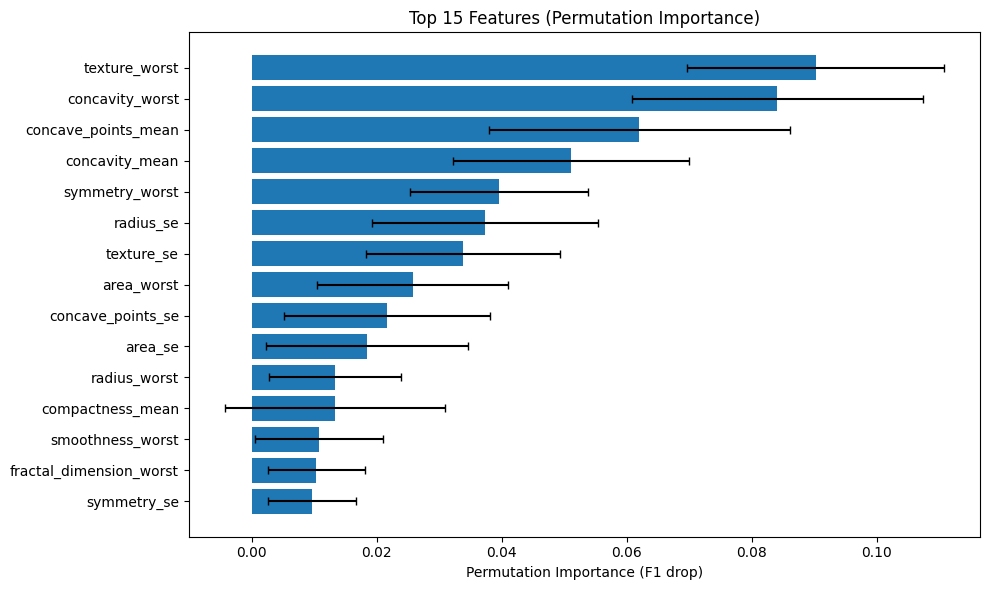

In [1]:
permutation = permutation_importance(
    logreg_model,
    X_test,
    y_test,
    n_repeats=30,
    random_state=RANDOM_STATE,
    scoring="f1"
)

importance_table = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": permutation.importances_mean,
    "importance_std": permutation.importances_std
}).sort_values("importance_mean", ascending=False).head(15)

plt.figure(figsize=(10, 6))
plt.barh(
    importance_table["feature"],
    importance_table["importance_mean"],
    xerr=importance_table["importance_std"],
    capsize=3
)
plt.xlabel("Permutation Importance (F1-score decrease)")
plt.title("Top 15 Features by Permutation Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 7. Conclusion

- Polynomial Logistic Regression achieved the strongest test-set result among the two evaluated models.
- With a cross-validation-selected threshold of **0.40**, it reached **0.9737 accuracy**, **0.9524 malignant recall**, and **0.9639 malignant F1-score**.
- Random Forest, using a cross-validation-selected threshold of **0.36**, reached **0.9649 accuracy** and **0.9286 malignant recall**.
- Threshold selection matters: the operating threshold changes the balance between false positives and false negatives.
- The evaluation is limited to one stratified train-test split and a small public benchmark dataset. Further validation would be required before any real-world or medical use.

### Limitations and Future Work

- Repeat the evaluation with nested cross-validation or repeated stratified splits to estimate performance variability.
- Compare additional models and calibration methods.
- Evaluate threshold choices against an explicit cost for false negatives and false positives.
- Validate on independent data before considering any practical application.

**Important:** This notebook is an educational machine-learning project. It is not a diagnostic tool and must not be used for medical decisions.

## Reproducibility

Run the notebook from the project root after placing `wdbc.data` in the same directory. Install the packages listed in `requirements.txt` before execution.